In [5]:
import time
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.optimize import curve_fit


In [6]:
def simular_cp(N, lam, tiempo, infectados_iniciales=1, rng=random):
    infectado = bytearray(N * N)
    if infectados_iniciales == 1:
        lista = [(N // 2) * N + N // 2]
    else:
        lista = rng.sample(range(N * N), infectados_iniciales)
    for x in lista:
        infectado[x] = 1

    t = 0.0
    tasa_sitio = 1 + 4 * lam          # cura (1) + 4 vecinos (lam c/u)
    p_cura = 1 / tasa_sitio
    while lista:
        n = len(lista)
        tasa_global = n * tasa_sitio                          # n infectados, cada uno con tasa 1 + 4*lam
        t += -np.log(1.0 - rng.random()) / tasa_global        # tiempo al próximo evento ~ Exp(tasa_global)
        if t >= tiempo:
            t = tiempo
            break
        k = rng.randrange(n)
        x = lista[k]
        if rng.random() < p_cura:                 # se cura
            ultimo = lista.pop()
            if k < n - 1:
                lista[k] = ultimo
            infectado[x] = 0
        else:                                     # intenta contagiar a un vecino
            i = x // N                            # fila del sitio x
            j = x % N                             # columna del sitio x
            di, dj = [(1, 0), (-1, 0), (0, 1), (0, -1)][rng.randrange(4)]  # abajo, arriba, derecha, izquierda
            i2, j2 = i + di, j + dj
            if 0 <= i2 < N and 0 <= j2 < N:       # borde abierto: fuera de la grilla no hay vecino
                y = i2 * N + j2
                if not infectado[y]:
                    infectado[y] = 1
                    lista.append(y)

    matriz = np.array(list(infectado)).reshape(N, N)
    return len(lista) > 0, t, len(lista), matriz

In [7]:
N = 40                                   # tamaño de la grilla (cuadrado de N x N sitios, bordes abiertos)
tiempo = 300.0                           # tiempo final: "sobrevivir" = seguir con infectados en t = 300
repeticiones = 200                       # corridas independientes por cada valor de lambda
cota_inf, cota_sup = 1/3, 0.79           # cotas teóricas para Z^2 (Liggett; Stacey)
lambdas = np.unique(np.round(np.concatenate([
    np.linspace(cota_inf, 0.45, 18),     # zona del crítico: paso ≈ 0.0069
    np.linspace(0.47, cota_sup, 9),      # zona supercrítica: paso = 0.04
]), 4))
probabilidades_supervivencia = []
print(f"Simulando {len(lambdas)} valores de lambda ({repeticiones} repeticiones c/u)...")
inicio = time.time()


for k in lambdas:
    exitos = 0
    for _ in range(repeticiones):
        sobrevivio, _, _, _ = simular_cp(N, k, tiempo, infectados_iniciales=1)
        if sobrevivio:
            exitos += 1
    alpha_hat = exitos / repeticiones
    probabilidades_supervivencia.append(alpha_hat)
    print(f"Lambda: {k:.4f} | alpha(lambda): {alpha_hat:.3f}")

final = time.time() - inicio
print(f"\nSimulación completada en {final:.2f} segundos.")

#  ---- Generado con apoyo de Inteligencia artificial, para mejorar la visualización del gráfico: Ajuste cerca del crítico: alpha(lambda) ~ A (lambda - lambda_c)^beta ----
prob_arr = np.array(probabilidades_supervivencia)
error_std = np.sqrt(prob_arr * (1 - prob_arr) / repeticiones)
def modelo(lam, A, lam_c, beta):
    return A * np.clip(lam - lam_c, 0, None) ** beta

usar = lambdas <= 0.48
p_seg = np.maximum(prob_arr[usar], 1 / repeticiones)
sigma = np.sqrt(p_seg * (1 - p_seg) / repeticiones)

try:
    par, cov = curve_fit(modelo, lambdas[usar], prob_arr[usar], p0=[2, 0.41, 0.6],
                         sigma=sigma, bounds=([0, 0.35, 0.1], [50, 0.45, 2]))
    A, lam_c, beta = par
    paso = lambdas[1] - lambdas[0]
    err_lam_c = paso

    print(f"\nAjuste: lambda_c = {lam_c:.4f} +- {err_lam_c:.4f}")
    print(f"Intervalo: [{lam_c - err_lam_c:.3f}, {lam_c + err_lam_c:.3f}]")
except RuntimeError:
    par = None
    print("\nEl ajuste no convergió: revisar el rango 'usar' o el valor inicial p0.")

#-----Fin IA
plt.figure(figsize=(8.5, 5))

if par is not None:
    plt.axvspan(lam_c - err_lam_c, lam_c + err_lam_c, color='crimson', alpha=0.12,
                label=rf'$\lambda_c \in [{lam_c - err_lam_c:.3f},\ {lam_c + err_lam_c:.3f}]$ (paso de la grilla)')
    plt.axvline(x=lam_c, color='crimson', linestyle='--', alpha=0.8,
                label=rf'$\hat{{\lambda}}_c \approx {lam_c:.3f}$')
plt.fill_between(lambdas, prob_arr - error_std, prob_arr + error_std,
                 color='b', alpha=0.15, linewidth=0, label='± 1 error estándar')
plt.plot(lambdas, prob_arr, marker='o', markersize=4, linestyle='-', color='b',
         label=r'$\hat{\alpha}(\lambda)$')
plt.xlabel(r'$\lambda$')
plt.ylabel(rf'$\alpha(\lambda))$ hasta $t = {tiempo:.0f}$')
plt.ylim(-0.02, max(0.5, prob_arr.max() + 0.05))
plt.grid(True, alpha=0.3)
plt.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()
#alguno de los axv fueron con apoyo de IA  porque todavía nos cuesta graficar :(

Simulando 27 valores de lambda (200 repeticiones c/u)...
Lambda: 0.3333 | alpha(lambda): 0.000
Lambda: 0.3402 | alpha(lambda): 0.000
Lambda: 0.3471 | alpha(lambda): 0.000
Lambda: 0.3539 | alpha(lambda): 0.000
Lambda: 0.3608 | alpha(lambda): 0.000
Lambda: 0.3676 | alpha(lambda): 0.000
Lambda: 0.3745 | alpha(lambda): 0.000
Lambda: 0.3814 | alpha(lambda): 0.000
Lambda: 0.3882 | alpha(lambda): 0.000
Lambda: 0.3951 | alpha(lambda): 0.000
Lambda: 0.4020 | alpha(lambda): 0.005
Lambda: 0.4088 | alpha(lambda): 0.005


KeyboardInterrupt: 

Simulando 25 valores de lambda (200 repeticiones c/u)...
Lambda: 0.3800 | alpha(lambda): 0.000
Lambda: 0.3871 | alpha(lambda): 0.000
Lambda: 0.3942 | alpha(lambda): 0.000
Lambda: 0.4012 | alpha(lambda): 0.000
Lambda: 0.4083 | alpha(lambda): 0.030
Lambda: 0.4154 | alpha(lambda): 0.075
Lambda: 0.4225 | alpha(lambda): 0.085
Lambda: 0.4296 | alpha(lambda): 0.155
Lambda: 0.4367 | alpha(lambda): 0.190
Lambda: 0.4438 | alpha(lambda): 0.250
Lambda: 0.4508 | alpha(lambda): 0.245
Lambda: 0.4579 | alpha(lambda): 0.220
Lambda: 0.4650 | alpha(lambda): 0.285
Lambda: 0.4721 | alpha(lambda): 0.280
Lambda: 0.4792 | alpha(lambda): 0.315
Lambda: 0.4863 | alpha(lambda): 0.315
Lambda: 0.4933 | alpha(lambda): 0.350
Lambda: 0.5004 | alpha(lambda): 0.315
Lambda: 0.5075 | alpha(lambda): 0.360
Lambda: 0.5146 | alpha(lambda): 0.455
Lambda: 0.5217 | alpha(lambda): 0.385
Lambda: 0.5288 | alpha(lambda): 0.380
Lambda: 0.5358 | alpha(lambda): 0.450
Lambda: 0.5429 | alpha(lambda): 0.465
Lambda: 0.5500 | alpha(lambda):

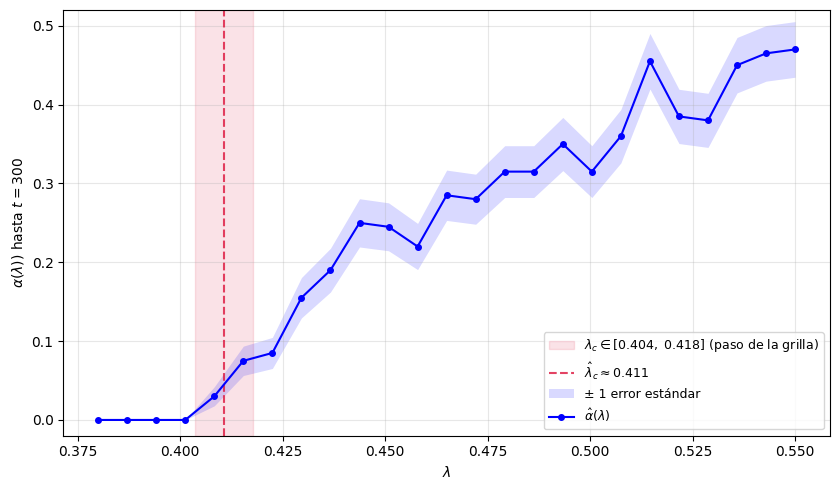

In [ ]:
N = 40
tiempo = 300.0
repeticiones = 200
lambdas = np.linspace(0.38, 0.55, 25)
probabilidades_supervivencia = []

print(f"Simulando {len(lambdas)} valores de lambda ({repeticiones} repeticiones c/u)...")
inicio = time.time()
for k in lambdas:
    exitos = 0
    for _ in range(repeticiones):
        sobrevivio, _, _, _ = simular_cp(N, k, tiempo, infectados_iniciales=1)
        if sobrevivio:
            exitos += 1
    alpha_hat = exitos / repeticiones
    probabilidades_supervivencia.append(alpha_hat)
    print(f"Lambda: {k:.4f} | alpha(lambda): {alpha_hat:.3f}")

final = time.time() - inicio
print(f"\nSimulación completada en {final:.2f} segundos.")

# ---- lo mismo que en el bloque de arriba
prob_arr = np.array(probabilidades_supervivencia)
error_std = np.sqrt(prob_arr * (1 - prob_arr) / repeticiones)
def modelo(lam, A, lam_c, beta):
    return A * np.clip(lam - lam_c, 0, None) ** beta
usar = lambdas <= 0.48
p_seg = np.maximum(prob_arr[usar], 1 / repeticiones)
sigma = np.sqrt(p_seg * (1 - p_seg) / repeticiones)

try:
    par, cov = curve_fit(modelo, lambdas[usar], prob_arr[usar], p0=[2, 0.41, 0.6],
                         sigma=sigma, bounds=([0, 0.35, 0.1], [50, 0.45, 2]))
    A, lam_c, beta = par
    paso = lambdas[1] - lambdas[0]
    err_lam_c = paso

    print(f"\nAjuste: lambda_c = {lam_c:.4f} +- {err_lam_c:.4f}")
    print(f"Intervalo: [{lam_c - err_lam_c:.3f}, {lam_c + err_lam_c:.3f}]")
except RuntimeError:
    par = None
    print("\nEl ajuste no convergió: revisar el rango 'usar' o el valor inicial p0.")

plt.figure(figsize=(8.5, 5))

if par is not None:
    plt.axvspan(lam_c - err_lam_c, lam_c + err_lam_c, color='crimson', alpha=0.12,
                label=rf'$\lambda_c \in [{lam_c - err_lam_c:.3f},\ {lam_c + err_lam_c:.3f}]$ (paso de la grilla)')
    plt.axvline(x=lam_c, color='crimson', linestyle='--', alpha=0.8,
                label=rf'$\hat{{\lambda}}_c \approx {lam_c:.3f}$')
plt.fill_between(lambdas, prob_arr - error_std, prob_arr + error_std,
                 color='b', alpha=0.15, linewidth=0, label='± 1 error estándar')
plt.plot(lambdas, prob_arr, marker='o', markersize=4, linestyle='-', color='b',
         label=r'$\hat{\alpha}(\lambda)$')
plt.xlabel(r'$\lambda$')
plt.ylabel(rf'$\alpha(\lambda))$ hasta $t = {tiempo:.0f}$')
plt.ylim(-0.02, max(0.5, prob_arr.max() + 0.05))
plt.grid(True, alpha=0.3)
plt.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
#Generados con ia, en el sentido de que agarra el codigo de arriba pero con los arrlegos que permiten generar y descargar frames
import os
import numpy as np
import random
import shutil
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image
import glob
import base64
from IPython.display import HTML, display


def simular_cp_video(N, lam, tiempo_max, num_frames=100, infectados_iniciales=1, rng=random):
    """Mismo proceso que simular_cp, pero guarda la grilla en num_frames + 1 tiempos equiespaciados."""
    infectado = bytearray(N * N)
    if infectados_iniciales == 1:
        lista = [(N // 2) * N + N // 2]
    else:
        lista = rng.sample(range(N * N), infectados_iniciales)
    for x in lista:
        infectado[x] = 1

    def foto():
        return np.frombuffer(bytes(infectado), dtype=np.uint8).reshape(N, N).astype(int)

    tiempos_frames = np.linspace(0, tiempo_max, num_frames + 1)
    historial_frames = [(foto(), 0.0)]
    f = 1

    t = 0.0
    tasa_sitio = 1 + 4 * lam
    p_cura = 1 / tasa_sitio
    while lista:
        n = len(lista)
        t += rng.expovariate(n * tasa_sitio)
        while f <= num_frames and tiempos_frames[f] < t:
            historial_frames.append((foto(), tiempos_frames[f]))
            f += 1
        if f > num_frames:
            break

        k = rng.randrange(n)
        x = lista[k]
        if rng.random() < p_cura:
            ultimo = lista.pop()
            if k < n - 1:
                lista[k] = ultimo
            infectado[x] = 0
        else:
            i, j = divmod(x, N)
            di, dj = ((1, 0), (-1, 0), (0, 1), (0, -1))[rng.randrange(4)]
            i2, j2 = i + di, j + dj
            if 0 <= i2 < N and 0 <= j2 < N:
                y = i2 * N + j2
                if not infectado[y]:
                    infectado[y] = 1
                    lista.append(y)
    while f <= num_frames:
        historial_frames.append((foto(), tiempos_frames[f]))
        f += 1

    return historial_frames

#fin IA

N_grilla = 100
frames_deseados = 240
infectados_iniciales = 1
lambdas_a_animar = [0.380, 0.411, 0.500, 0.900]
nombres_fases = ["Subcritico", "Critico", "Supercritico", "Supercritico"]
t_max_por_fase = [150, 1000, 300, 120]
max_intentos = 300
colores = ListedColormap(['#FEF3C7', '#991B1B'])

fps = 16
carpeta_raiz = 'img'
lineas_latex = []

#generado con ia, simplemente para que permita descargar y se rescanten los mejores frames del video
shutil.rmtree(carpeta_raiz, ignore_errors=True)
for viejo in glob.glob('proceso_contacto_*.gif') + glob.glob('cuadros_overleaf.zip'):
    os.remove(viejo)

def duracion_y_tamano(fotogramas):
    """Último cuadro con infectados y máximo de infectados (para elegir la mejor corrida)."""
    vivos = [i for i, (m, _) in enumerate(fotogramas) if m.sum() > 0]
    return (vivos[-1] if vivos else 0, max(int(m.sum()) for m, _ in fotogramas))

for lam, fase, t_max_video in zip(lambdas_a_animar, nombres_fases, t_max_por_fase):
    print(f"\n--- Procesando Lambda = {lam} ({fase}) ---")
    mejor, mejor_puntaje, mejor_semilla = None, (-1, -1), None
    for semilla in range(max_intentos):
        fot = simular_cp_video(N_grilla, lam, t_max_video, frames_deseados,
                               infectados_iniciales=infectados_iniciales,
                               rng=random.Random(semilla))
        puntaje = duracion_y_tamano(fot)
        if puntaje > mejor_puntaje:
            mejor, mejor_puntaje, mejor_semilla = fot, puntaje, semilla
        if puntaje[0] == frames_deseados:
            break
    fotogramas = mejor
    print(f"Semilla elegida: {mejor_semilla} (máx. {mejor_puntaje[1]} infectados)")
    nombre = f'contacto-{fase.lower()}-{lam:.3f}'.replace('.', 'p')
    carpeta = os.path.join(carpeta_raiz, nombre)
    os.makedirs(carpeta, exist_ok=True)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_xticks([])
    ax.set_yticks([])
    im = ax.imshow(fotogramas[0][0], cmap=colores, vmin=0, vmax=1)
    titulo = ax.set_title('', fontsize=12)

    rutas_png = []
    for i, (matriz_frame, tiempo_frame) in enumerate(fotogramas):
        im.set_data(matriz_frame)
        n_inf = int(matriz_frame.sum())
        titulo.set_text(rf'$\lambda={lam:.3f}$ ({fase}) | t = {tiempo_frame:.1f} | Infectados: {n_inf}')
        ruta = os.path.join(carpeta, f'{nombre}-{i}.png')
        fig.savefig(ruta, dpi=100)
        rutas_png.append(ruta)
    plt.close(fig)
    imagenes = [Image.open(r).convert('RGB') for r in rutas_png]
    duraciones = [int(1000 / fps)] * len(imagenes)
    duraciones[-1] += 2000
    archivo_gif = f'proceso_contacto_{fase}_{lam:.3f}.gif'
    imagenes[0].save(archivo_gif, save_all=True, append_images=imagenes[1:],
                     duration=duraciones, loop=0)
    print(f"¡Guardado: {archivo_gif} y {len(rutas_png)} cuadros en {carpeta}/!")
    ultimo = len(rutas_png) - 1
    lineas_latex.append(
        f'\\insertanimatedimage[\\label{{img:{nombre}}}]{{{nombre}/{nombre}}}'
        f'{{width=6cm}}{{{fps}}}{{{ultimo}}}{{Proceso de contacto, $\\lambda = {lam:.3f}$ ({fase}).}}'
    )
shutil.make_archive('cuadros_overleaf', 'zip', '.', carpeta_raiz)
print("\nZip listo: cuadros_overleaf.zip")

print("\n===== Código LaTeX para tu presentación =====")
for linea in lineas_latex:
    print(linea)
def enlace_descarga(ruta):
    with open(ruta, 'rb') as f:
        datos = base64.b64encode(f.read()).decode()
    tipo = 'application/zip' if ruta.endswith('.zip') else 'image/gif'
    nombre = os.path.basename(ruta)
    tam = os.path.getsize(ruta) / 1e6
    return (f'<a download="{nombre}" href="data:{tipo};base64,{datos}" '
            f'style="font-size:16px">⬇️ Descargar {nombre} ({tam:.1f} MB)</a><br>')

archivos = ['cuadros_overleaf.zip'] + sorted(glob.glob('proceso_contacto_*.gif'))
display(HTML(''.join(enlace_descarga(a) for a in archivos)))

print("\n¡Listo! Haz clic en los enlaces de arriba para descargar.")


--- Procesando Lambda = 0.38 (Subcritico) ---
Semilla elegida: 267 (máx. 39 infectados)
¡Guardado: proceso_contacto_Subcritico_0.380.gif y 241 cuadros en img/contacto-subcritico-0p380/!

--- Procesando Lambda = 0.411 (Critico) ---
Semilla elegida: 54 (máx. 349 infectados)
¡Guardado: proceso_contacto_Critico_0.411.gif y 241 cuadros en img/contacto-critico-0p411/!

--- Procesando Lambda = 0.5 (Supercritico) ---
Semilla elegida: 5 (máx. 3570 infectados)
¡Guardado: proceso_contacto_Supercritico_0.500.gif y 241 cuadros en img/contacto-supercritico-0p500/!

--- Procesando Lambda = 0.9 (Supercritico) ---
Semilla elegida: 1 (máx. 7019 infectados)


In [ ]:
#exactamente lo mismo que el bloque de arriba
N_grilla = 100
lam = 0.380
infectados_iniciales = N_grilla * N_grilla
frames_deseados = 240
fps = 16
pixeles_por_celda = 5
semilla = 0
color_sano = (0xFE, 0xF3, 0xC7)
color_infectado = (0x99, 0x1B, 0x1B)

nombre = f'contacto-limpio-{lam:.3f}'.replace('.', 'p')
carpeta = os.path.join('img', nombre)
shutil.rmtree(carpeta, ignore_errors=True)
os.makedirs(carpeta)
prueba = simular_cp_video(N_grilla, lam, 5000, 500,
                          infectados_iniciales=infectados_iniciales,
                          rng=random.Random(semilla))
vivos = [t for m, t in prueba if m.sum() > 0]
t_extincion = vivos[-1] + (prueba[1][1] - prueba[0][1])
t_max_video = 1.05 * t_extincion
print(f"Se extingue cerca de t = {t_extincion:.0f}; el video llega hasta t = {t_max_video:.0f}")
fotogramas = simular_cp_video(N_grilla, lam, t_max_video, frames_deseados,
                              infectados_iniciales=infectados_iniciales,
                              rng=random.Random(semilla))
paleta = np.array([color_sano, color_infectado], dtype=np.uint8)
rutas_png = []
for i, (matriz, _) in enumerate(fotogramas):
    rgb = paleta[matriz]
    rgb = rgb.repeat(pixeles_por_celda, axis=0).repeat(pixeles_por_celda, axis=1)
    ruta = os.path.join(carpeta, f'{nombre}-{i}.png')
    Image.fromarray(rgb).save(ruta, optimize=True)
    rutas_png.append(ruta)
imagenes = [Image.open(r) for r in rutas_png]
duraciones = [int(1000 / fps)] * len(imagenes)
duraciones[-1] += 2000
archivo_gif = f'proceso_contacto_limpio_{lam:.3f}.gif'
imagenes[0].save(archivo_gif, save_all=True, append_images=imagenes[1:],
                 duration=duraciones, loop=0)
archivo_zip = f'cuadros_{nombre}'
shutil.make_archive(archivo_zip, 'zip', '.', carpeta)
archivo_zip += '.zip'
print(f"¡Listo! {len(rutas_png)} cuadros en {carpeta}/, {archivo_gif} y {archivo_zip}")
ultimo = len(rutas_png) - 1
print("\n===== Código LaTeX =====")
print(f'\\insertanimatedimage{{{nombre}/{nombre}}}{{width=6cm}}{{{fps}}}{{{ultimo}}}{{}}   % leyenda vacía = sin texto')
def enlace_descarga(ruta):
    with open(ruta, 'rb') as f:
        datos = base64.b64encode(f.read()).decode()
    tipo = 'application/zip' if ruta.endswith('.zip') else 'image/gif'
    return (f'<a download="{os.path.basename(ruta)}" href="data:{tipo};base64,{datos}" '
            f'style="font-size:16px">⬇️ Descargar {os.path.basename(ruta)} '
            f'({os.path.getsize(ruta) / 1e6:.1f} MB)</a><br>')

display(HTML(enlace_descarga(archivo_zip) + enlace_descarga(archivo_gif)))

Estudio Cajetas

In [ ]:
def tiempos_de_llegada(N, lam, n_max, radio_caja=2, rng=random):
    c = N // 2
    infectado = bytearray(N * N)            # 0 sano, 1 infectado; el sitio (i, j) está en i*N + j
    lista = []                              # sitios infectados
    for a in range(-radio_caja, radio_caja + 1):
        for b in range(-radio_caja, radio_caja + 1):
            x = (c + a) * N + (c + b)
            infectado[x] = 1
            lista.append(x)

    # ---- Tiempos de llegada en la dirección (0,1) ----
    T = np.full(n_max + 1, np.nan)          # T[d] = primer tiempo en que se infecta el punto a distancia d
    T[:radio_caja + 1] = 0.0

    t = 0.0
    tasa_sitio = 1 + 4 * lam                # cura (tasa 1) + 4 vecinos (tasa lam c/u)
    p_cura = 1 / tasa_sitio

    # ---- Simulación: hasta que se extinga o llegue a distancia n_max ----
    while lista and faltan > 0:
        n = len(lista)
        t += rng.expovariate(n * tasa_sitio)            # tiempo al próximo evento ~ Exp(n * tasa_sitio)
        k = rng.randrange(n)
        x = lista[k]

        if rng.random() < p_cura:                       # x se cura
            ultimo = lista.pop()
            if k < n - 1:
                lista[k] = ultimo
            infectado[x] = 0

        else:                                           # x intenta contagiar a un vecino al azar
            i = x // N
            j = x % N
            di, dj = [(1, 0), (-1, 0), (0, 1), (0, -1)][rng.randrange(4)]
            i2, j2 = i + di, j + dj
            if 0 <= i2 < N and 0 <= j2 < N:
                y = i2 * N + j2
                if not infectado[y]:
                    infectado[y] = 1
                    lista.append(y)
                    d = j2 - c
                    if i2 == c and 0 < d <= n_max and np.isnan(T[d]):
                        T[d] = t
                        faltan -= 1

    return T
    if faltan > 0:
        return None        # la infección se extinguió antes de llegar a distancia n_max
    return T               # tiempos de primera llegada a distancia 0, 1,

In [ ]:
# ---- Parámetros ----
n_max = 60
N = 4 * n_max
repeticiones = 20
lambdas_vel = [0.45, 0.5, 0.55, 0.6, 0.7, 0.8, 1.0, 1.5]

distancias = np.arange(n_max + 1)
velocidades = []
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
inicio = time.time()
for lam in lambdas_vel:
    corridas = []
    while len(corridas) < repeticiones:
        T = tiempos_de_llegada(N, lam, n_max)
        if T is not None:
            corridas.append(T)
    T_medio = np.mean(corridas, axis=0)
    lejos = distancias >= n_max // 2
    pendiente = np.polyfit(distancias[lejos], T_medio[lejos], 1)[0]   # pendiente = 1/v
    v = 1 / pendiente                            # velocidad: sitios avanzados por unidad de tiempo
    velocidades.append(v)
    print(f"Lambda: {lam:.2f} | velocidad v = {v:.3f}")
    ax[0].plot(distancias[1:], T_medio[1:] / distancias[1:], label=rf'$\lambda={lam}$')

print(f"\nSimulación completada en {time.time() - inicio:.1f} segundos.")
ax[0].set_xlabel('n')
ax[0].set_ylabel(r'$t(n\,(0,1))\,/\,n$')
ax[0].set_title(r'Tiempo de llegada por unidad de distancia ($\to 1/v$)')
ax[0].grid(True, alpha=0.3)
ax[0].legend()
ax[1].plot(lambdas_vel, velocidades, marker='o', color='b')
ax[1].set_xlabel(r'Tasa de Infección ($\lambda$)')
ax[1].set_ylabel('Velocidad de propagación $v$')
ax[1].set_title('Velocidad en la dirección (0,1)')
ax[1].set_ylim(bottom=0)
ax[1].grid(True, alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
#analogo a lo comentado con lo videos de arriba, se reescribe el codigo para que ahora sea capaz de guardar frames
from matplotlib.patches import Circle

def simular_cp_video_caja(N, lam, tiempo_max, num_frames=60, radio_caja=2, rng=random):
    """Proceso de contacto desde una caja infectada en el centro.
    Guarda (matriz, t, alcance) en num_frames + 1 tiempos equiespaciados, donde alcance es
    la distancia más lejana a la que llegó la infección en la dirección (0,1)."""
    c = N // 2
    infectado = bytearray(N * N)
    lista = []
    for a in range(-radio_caja, radio_caja + 1):          # caja inicial infectada
        for b in range(-radio_caja, radio_caja + 1):
            x = (c + a) * N + (c + b)
            infectado[x] = 1
            lista.append(x)
    alcance = radio_caja

    def foto():
        return np.frombuffer(bytes(infectado), dtype=np.uint8).reshape(N, N).astype(int)

    tiempos_frames = np.linspace(0, tiempo_max, num_frames + 1)
    frames = [(foto(), 0.0, alcance)]
    f = 1

    t = 0.0
    tasa_sitio = 1 + 4 * lam
    p_cura = 1 / tasa_sitio
    while lista:
        n = len(lista)
        t += rng.expovariate(n * tasa_sitio)
        while f <= num_frames and tiempos_frames[f] < t:      # fotos hasta el próximo evento
            frames.append((foto(), tiempos_frames[f], alcance))
            f += 1
        if f > num_frames:
            break

        k = rng.randrange(n)
        x = lista[k]
        if rng.random() < p_cura:                 # se cura
            ultimo = lista.pop()
            if k < n - 1:
                lista[k] = ultimo
            infectado[x] = 0
        else:                                     # intenta contagiar a un vecino
            i, j = divmod(x, N)
            y = (((i + 1) % N) * N + j, ((i - 1) % N) * N + j,
                 i * N + (j + 1) % N, i * N + (j - 1) % N)[rng.randrange(4)]
            if not infectado[y]:
                infectado[y] = 1
                lista.append(y)
                fila, col = divmod(y, N)
                if fila == c and col - c > alcance:            # nuevo récord en la dirección (0,1)
                    alcance = col - c

    sobrevivio = len(lista) > 0
    return frames, sobrevivio

In [ ]:
#analogo a lo comentado con lo videos de arriba, se reescribe el codigo para que ahora sea capaz de guardar frames
from matplotlib import animation
from matplotlib.colors import ListedColormap
from google.colab import files

N_grilla = 151
t_max_video = 35.0
frames_deseados = 70
radio_caja = 2
lambdas_video = [0.45, 0.6, 1.0]
v_medida = {0.45: 0.22, 0.6: 0.68, 1.0: 1.62}
colores = ListedColormap(['#FEF3C7', '#991B1B'])
c = N_grilla // 2

videos = {}
for lam in lambdas_video:
    intentos = 0
    while True:
        intentos += 1
        frames, sobrevivio = simular_cp_video_caja(N_grilla, lam, t_max_video, frames_deseados, radio_caja)
        if sobrevivio:
            break
    videos[lam] = frames
    print(f"Lambda = {lam}: listo ({intentos} intento(s))")

fig, axes = plt.subplots(1, 3, figsize=(15, 5.8))
fig.suptitle('Propagación desde una caja 5×5 (mismo tiempo en los tres paneles)', fontsize=14)
fig.subplots_adjust(left=0.01, right=0.99, bottom=0.02, top=0.80, wspace=0.06)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
    ax.plot([c, N_grilla - 1], [c, c], color='gray', lw=0.8, alpha=0.6)

cuadros = []
for f in range(frames_deseados + 1):
    artistas = []
    for ax, lam in zip(axes, lambdas_video):
        matriz, t_f, alcance = videos[lam][f]
        im = ax.imshow(matriz, cmap=colores, vmin=0, vmax=1, animated=True)

        circ = Circle((c, c), radio_caja + v_medida[lam] * t_f, fill=False, ls='--',
                      lw=1.2, color='#1D4ED8', animated=True)
        ax.add_patch(circ)
        punto, = ax.plot([c + alcance], [c], 'o', color='#1D4ED8', ms=5, animated=True)
        texto = (rf'$\lambda={lam}$  |  t = {t_f:.1f}' + '\n' +
                 f'alcance en (0,1): {alcance}  |  v medida = {v_medida[lam]}')
        txt = ax.text(0.5, 1.02, texto, transform=ax.transAxes, ha='center', fontsize=11, animated=True)
        artistas += [im, circ, punto, txt]
    cuadros.append(artistas)

print("Ensamblando video...")
ani = animation.ArtistAnimation(fig, cuadros, interval=120, blit=True, repeat_delay=2000)
archivo_salida = 'velocidad_propagacion.gif'
ani.save(archivo_salida, writer='pillow')
plt.close(fig)
print(f"¡Guardado: {archivo_salida}!")

files.download(archivo_salida)